# Análise Exploratória — TMDB 5000 Movies

## Contexto
Com os dados limpos, partimos para responder as perguntas de negócio.
Cada seção abaixo investiga um aspecto diferente do que define o sucesso financeiro de um filme.

## Problema de Negócio
Um estúdio de cinema quer entender quais fatores influenciam a receita de um filme
para tomar decisões mais inteligentes de investimento antes do lançamento.

## Perguntas que vamos responder
1. Filmes com maior orçamento faturam mais?
2. Qual gênero tem a maior receita média?
3. A produção de filmes cresceu ao longo dos anos?
4. Quais são os 10 filmes mais lucrativos?
5. Existe relação entre nota do público e receita?

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

%matplotlib inline
sns.set_theme(style='whitegrid')

In [7]:
# Carrega o dataset limpo gerado no notebook 02
df = pd.read_csv('../data/processed/tmdb_limpo.csv')

df.shape

(3229, 19)

## 1. Orçamento x Receita

Filmes com maior investimento tendem a arrecadar mais?
Essa é a pergunta mais direta para o problema de negócio.

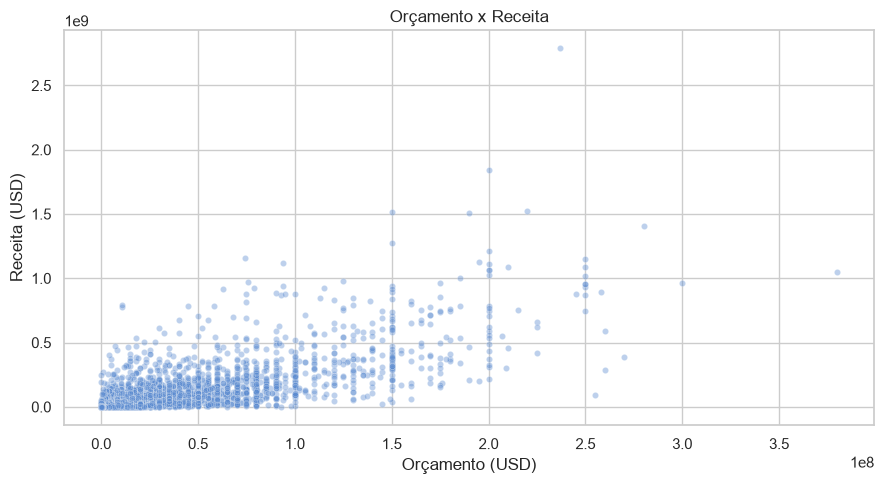

Correlação de Pearson: 0.71


In [8]:
# Relação entre orçamento e receita
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x='budget',
    y='revenue',
    alpha=0.4,
    s=20,
    color='#5b8bd0'
)
plt.xlabel('Orçamento (USD)')
plt.ylabel('Receita (USD)')
plt.title('Orçamento x Receita')
plt.tight_layout()
plt.savefig('../images/01_orcamento_x_receita.png', dpi=100)
plt.show()

corr = df['budget'].corr(df['revenue'])
print(f'Correlação de Pearson: {corr:.2f}')

## 2. Receita Média por Gênero

Quais gêneros de filme tendem a gerar mais receita?
Essa análise ajuda o estúdio a decidir em qual tipo de produção investir.

In [9]:
# Extrai o primeiro gênero de cada filme a partir da coluna JSON
def extrair_genero(texto):
    try:
        lista = ast.literal_eval(texto)
        return lista[0]['name'] if lista else None
    except:
        return None

df['genero_principal'] = df['genres'].apply(extrair_genero)

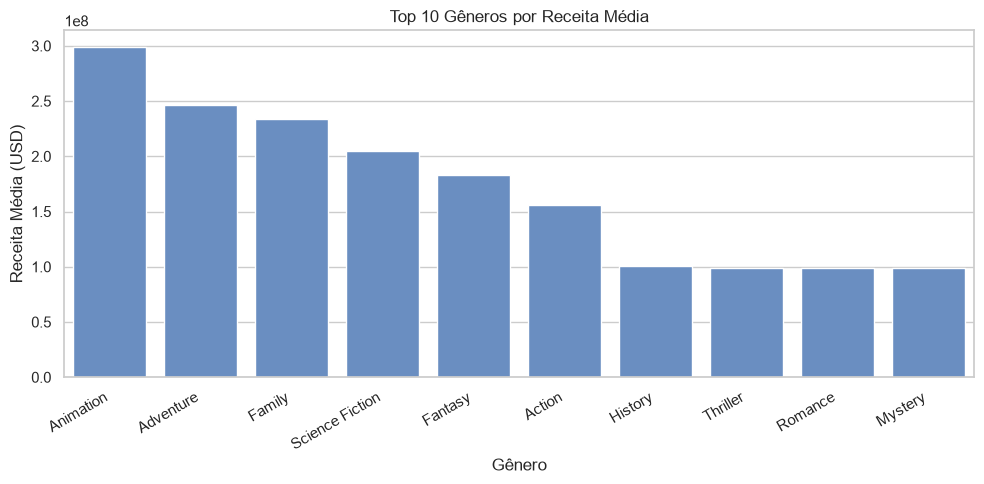

In [10]:
# Receita média por gênero — top 10
receita_genero = (
    df.groupby('genero_principal')['revenue']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=receita_genero.index, y=receita_genero.values, color='#5b8bd0')
plt.xlabel('Gênero')
plt.ylabel('Receita Média (USD)')
plt.title('Top 10 Gêneros por Receita Média')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../images/02_receita_por_genero.png', dpi=100)
plt.show()

## 3. Produção de Filmes ao Longo dos Anos

O mercado cinematográfico cresceu? Quantos filmes foram produzidos por ano?

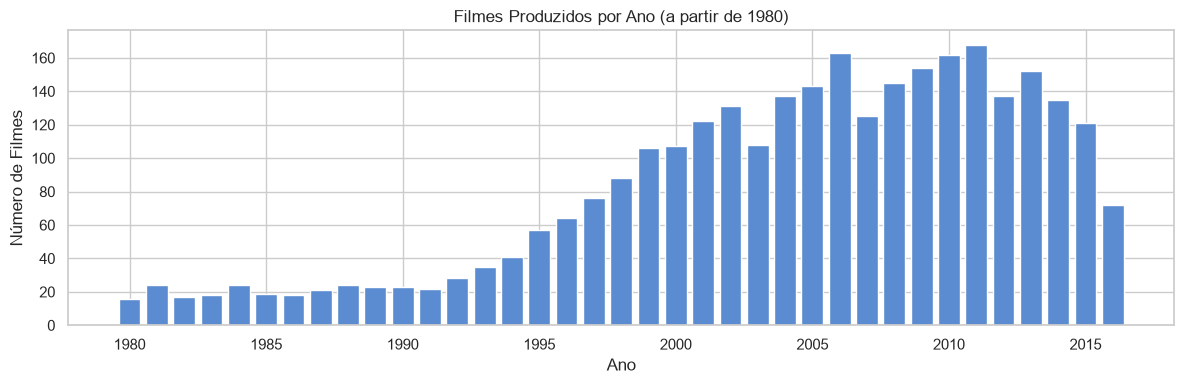

In [11]:
# Filmes por ano de lançamento a partir de 1980
filmes_por_ano = (
    df[df['release_year'] >= 1980]['release_year']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 4))
plt.bar(filmes_por_ano.index, filmes_por_ano.values, color='#5b8bd0', width=0.8)
plt.xlabel('Ano')
plt.ylabel('Número de Filmes')
plt.title('Filmes Produzidos por Ano (a partir de 1980)')
plt.tight_layout()
plt.savefig('../images/03_filmes_por_ano.png', dpi=100)
plt.show()

## 4. Top 10 Filmes Mais Lucrativos

Lucro = Receita - Orçamento.
Quais filmes geraram o maior retorno financeiro?

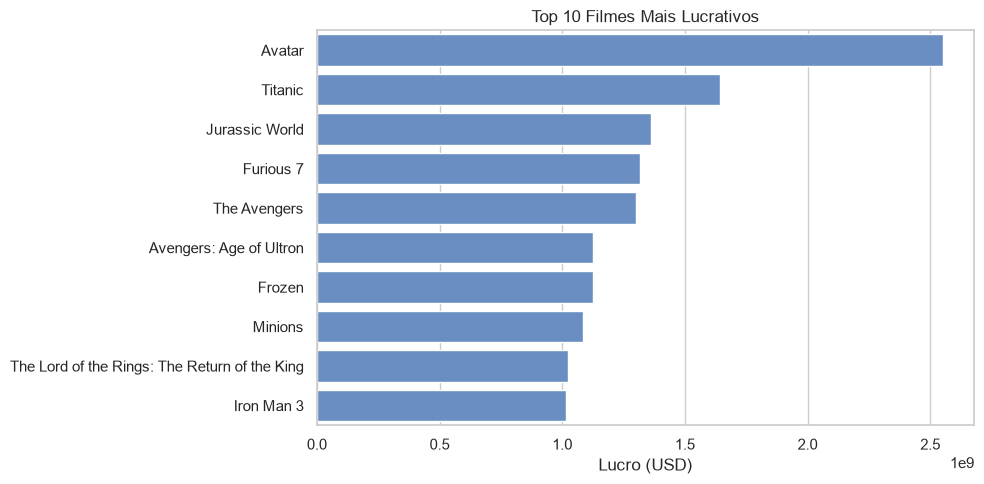

In [12]:
# Calcula o lucro de cada filme
df['lucro'] = df['revenue'] - df['budget']

top10_lucro = df.nlargest(10, 'lucro')[['title', 'lucro']].reset_index(drop=True)

plt.figure(figsize=(10, 5))
sns.barplot(data=top10_lucro, x='lucro', y='title', color='#5b8bd0')
plt.xlabel('Lucro (USD)')
plt.ylabel('')
plt.title('Top 10 Filmes Mais Lucrativos')
plt.tight_layout()
plt.savefig('../images/04_top10_lucro.png', dpi=100)
plt.show()

## 5. Nota do Público x Receita

Filmes bem avaliados necessariamente faturam mais?
Ou qualidade e bilheteria são coisas diferentes?

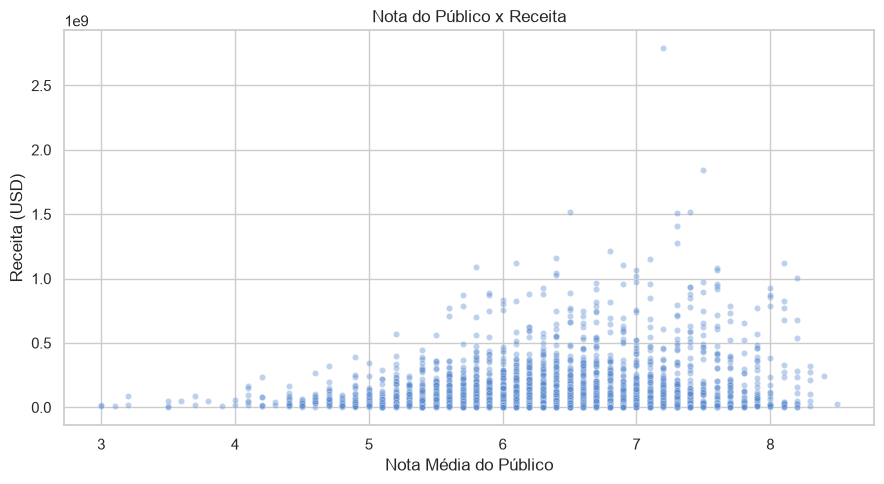

Correlação nota x receita: 0.17


In [13]:
# Filtra filmes com votos suficientes para ter nota representativa
df_avaliados = df[df['vote_count'] > 100]

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_avaliados,
    x='vote_average',
    y='revenue',
    alpha=0.4,
    s=20,
    color='#5b8bd0'
)
plt.xlabel('Nota Média do Público')
plt.ylabel('Receita (USD)')
plt.title('Nota do Público x Receita')
plt.tight_layout()
plt.savefig('../images/05_nota_x_receita.png', dpi=100)
plt.show()

corr_nota = df_avaliados['vote_average'].corr(df_avaliados['revenue'])
print(f'Correlação nota x receita: {corr_nota:.2f}')

## Conclusões

- **Orçamento x Receita:** existe correlação positiva moderada — filmes com maior investimento tendem a arrecadar mais, mas não é uma regra absoluta
- **Gênero:** animação e aventura lideram em receita média, indicando que são apostas mais seguras para o estúdio
- **Produção ao longo do tempo:** a quantidade de filmes produzidos cresceu significativamente a partir dos anos 2000
- **Top 10 lucrativos:** franquias dominam — Avatar, Star Wars e filmes da Marvel aparecem no topo
- **Nota x Receita:** a correlação é baixa — um filme pode ser muito bem avaliado e faturar pouco, e vice-versa